# QuietTracE — experiments

Notebook para iterar sobre el modelo y el QAOA **fuera de Qollab**, con vuestro
entorno Python. Reutiliza los módulos del repo:

- `quantum/modelo.py`   — modelo (rutas, conflictos, pesos geométricos, Ising, exacto)
- `quantum/fastqaoa.py` — QAOA exacto y rápido (NumPy)
- `quantum/qaoa.py`     — circuito QAOA para backend (ángulos numéricos, sin parámetros libres)
- `quantum/pipeline.py` — orquestación (problem, distribución, mejor solución)

Ejecutad las celdas en orden y ajustad parámetros en cada sección.

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))  # raíz del repo (notebook en notebooks/)

import numpy as np
import matplotlib.pyplot as plt

from quantum import modelo as M
from quantum import fastqaoa, qaoa, pipeline

np.set_printoptions(precision=4, suppress=True)
print("numpy", np.__version__)

numpy 2.5.3


## 1. Problema: variables y restricciones (antes de optimizar)

In [3]:
prob = pipeline._problem()
nets = prob["nets"]; n = len(nets)

print("redes:", nets)
print("conflictos (restricciones):")
for i, j in sorted(prob["conflicts"]):
    print("  ", nets[i], "-", nets[j])
print("vías por red (L4):", float(prob["vias"][0]), "| lambda_v:", prob["lam_v"])
print("M (penalización de conflicto):", round(prob["M"], 4))
print("h (campos Ising):", np.round(prob["h"], 3))

redes: ['D0', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'CLK']
conflictos (restricciones):
   D0 - D2
   D0 - D4
   D1 - D2
   D1 - D4
   D3 - D4
   D6 - D7
vías por red (L4): 2.0 | lambda_v: 0.5
M (penalización de conflicto): 8.0492
h (campos Ising): [-0.5 -0.5 -0.5 -0.5 -0.5 -0.5 -0.5 -0.5 -0.5]


## 2. Óptimo exacto (referencia, 2^n)

In [4]:
exact_cost, exact_bits = M.solve_exact(prob["W"], prob["vias"], prob["lam_v"], prob["conflicts"], prob["M"])
exact_bits = [int(b) for b in exact_bits]
print("costo óptimo:", round(exact_cost, 5), "| bits:", exact_bits)
print("L1:", [nets[i] for i,b in enumerate(exact_bits) if b==0])
print("L4:", [nets[i] for i,b in enumerate(exact_bits) if b==1])

costo óptimo: 7.04918 | bits: [0, 0, 1, 0, 1, 0, 0, 1, 0]
L1: ['D0', 'D1', 'D3', 'D5', 'D6', 'CLK']
L4: ['D2', 'D4', 'D7']


## 3. QAOA: optimización y convergencia

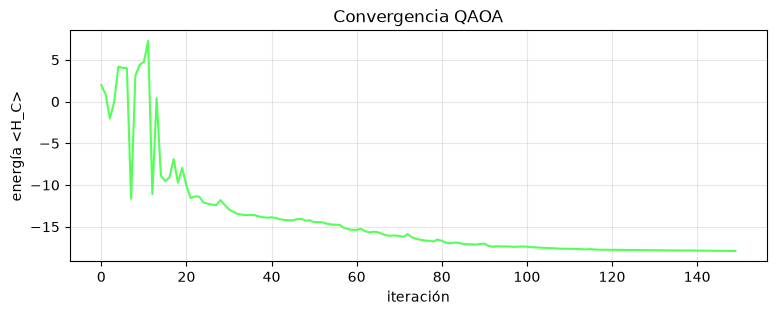

energía final: -17.905 | parámetros: 6


In [5]:
REPS, MAXITER = 3, 150
qa = fastqaoa.run_qaoa(prob["J"], prob["h"], reps=REPS, maxiter=MAXITER)

plt.figure(figsize=(9,3))
plt.plot(qa["history"], color="#54ff57")
plt.xlabel("iteración"); plt.ylabel("energía <H_C>")
plt.title("Convergencia QAOA"); plt.grid(True, alpha=.3); plt.show()
print("energía final:", round(qa["energy"], 4), "| parámetros:", qa["num_parameters"])

## 4. Solución QAOA + distribución

In [6]:
dist = pipeline._distribution(qa["probabilities"], prob["W"], prob["vias"], prob["lam_v"], prob["conflicts"], prob["M"], n)
best = pipeline._best_feasible(dist)

print("mejor QAOA:", best["x"], "| costo", best["cost"])
print("óptimo exacto:", exact_bits, "| costo", round(exact_cost, 5))
print("¿coincide con el óptimo?", best["x"] == exact_bits)
print("gap:", round((best["cost"] - exact_cost) / abs(exact_cost), 6))
print("L1:", [nets[i] for i,b in enumerate(best["x"]) if b==0])
print("L4:", [nets[i] for i,b in enumerate(best["x"]) if b==1])

mejor QAOA: [0, 0, 1, 0, 1, 0, 0, 1, 0] | costo 7.049177
óptimo exacto: [0, 0, 1, 0, 1, 0, 0, 1, 0] | costo 7.04918
¿coincide con el óptimo? True
gap: -0.0
L1: ['D0', 'D1', 'D3', 'D5', 'D6', 'CLK']
L4: ['D2', 'D4', 'D7']


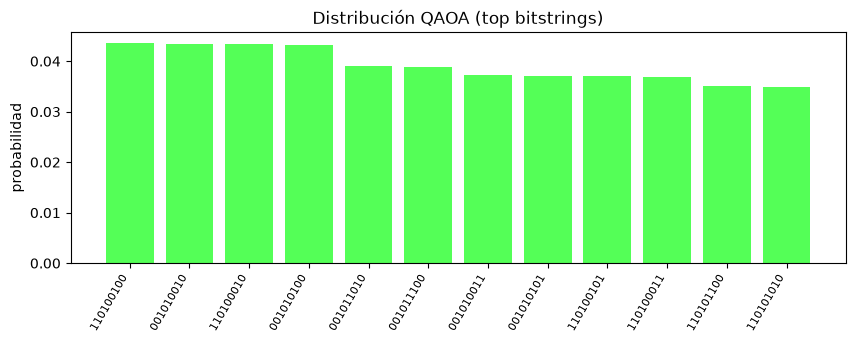

In [7]:
top = dist[:12]
labels = ["".join(map(str, d["x"])) for d in top]
colors = ["#54ff57" if d["feasible"] else "#ff6b6b" for d in top]
plt.figure(figsize=(10,3))
plt.bar(range(len(top)), [d["prob"] for d in top], color=colors)
plt.xticks(range(len(top)), labels, rotation=60, ha="right", fontsize=8)
plt.ylabel("probabilidad"); plt.title("Distribución QAOA (top bitstrings)"); plt.show()

## 5. Circuito QAOA (ángulos numéricos) + muestreo local

parámetros libres: 0 | profundidad: 41
puertas: {'rzz': 108, 'rz': 27, 'rx': 27, 'h': 9, 'measure': 9, 'barrier': 1}


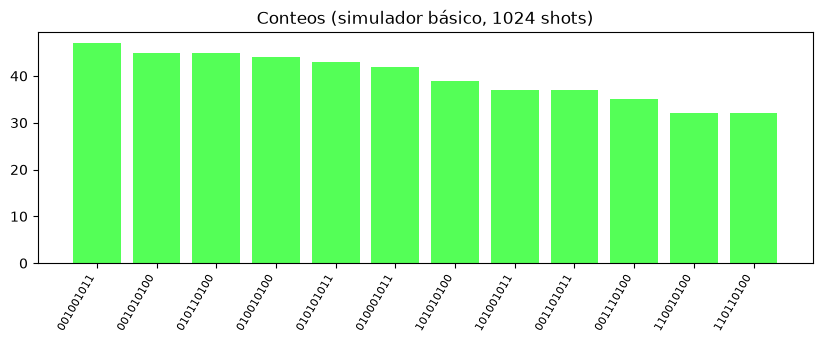

In [8]:
circ = qaoa.build_circuit(prob["J"], prob["h"], REPS, qa["theta"])
print("parámetros libres:", len(circ.parameters), "| profundidad:", circ.depth())
print("puertas:", dict(circ.count_ops()))

from qiskit.providers.basic_provider import BasicSimulator
counts = BasicSimulator().run(circ, shots=1024).result().get_counts()
topc = sorted(counts.items(), key=lambda kv: -kv[1])[:12]
plt.figure(figsize=(10,3))
plt.bar(range(len(topc)), [c for _,c in topc], color="#54ff57")
plt.xticks(range(len(topc)), [k for k,_ in topc], rotation=60, ha="right", fontsize=8)
plt.title("Conteos (simulador básico, 1024 shots)"); plt.show()

## 6. Simulador con ruido (opcional, requiere qiskit-aer)

In [9]:
try:
    from qiskit_aer import AerSimulator
    from qiskit_aer.noise import NoiseModel, depolarizing_error
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(0.01, 2), ["rzz"])
    nm.add_all_qubit_quantum_error(depolarizing_error(0.005, 1), ["rz", "rx", "h"])
    sim = AerSimulator(noise_model=nm)
    rc = sim.run(circ, shots=1024).result().get_counts()
    print("top con ruido:", sorted(rc.items(), key=lambda kv:-kv[1])[:6])
except Exception as e:
    print("qiskit-aer no disponible:", e)

qiskit-aer no disponible: No module named 'qiskit_aer'


## 7. IonQ (opcional, requiere qiskit-ionq y IONQ_API_KEY)

In [10]:
import os
try:
    from qiskit_ionq import IonQProvider
    token = os.environ.get("IONQ_API_KEY")
    assert token, "exporta IONQ_API_KEY antes de correr esta celda"
    backend = IonQProvider(token).get_backend("ionq_forte")  # o un simulador IonQ
    # NO transpilar para IonQ: enviar el circuito como está (ángulos numéricos válidos)
    job = backend.run(circ, shots=1024)
    print("job:", job.job_id())
    print("counts:", sorted(job.result().get_counts().items(), key=lambda kv:-kv[1])[:8])
except Exception as e:
    print("IonQ no disponible:", e)

IonQ no disponible: No module named 'qiskit_ionq'


## 8. Barridos de parámetros

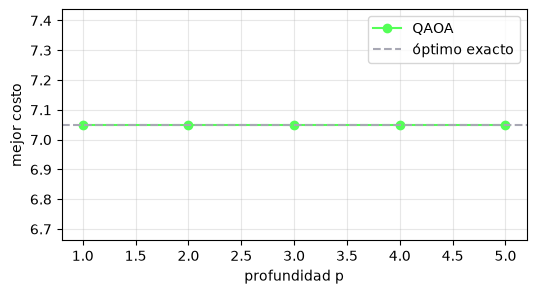

In [11]:
# profundidad p
ps = [1, 2, 3, 4, 5]
costs = []
for p in ps:
    q = fastqaoa.run_qaoa(prob["J"], prob["h"], reps=p, maxiter=120)
    d = pipeline._distribution(q["probabilities"], prob["W"], prob["vias"], prob["lam_v"], prob["conflicts"], prob["M"], n)
    costs.append(pipeline._best_feasible(d)["cost"])
plt.figure(figsize=(6,3))
plt.plot(ps, costs, "o-", color="#54ff57", label="QAOA")
plt.axhline(exact_cost, ls="--", color="#a8a8b4", label="óptimo exacto")
plt.xlabel("profundidad p"); plt.ylabel("mejor costo"); plt.legend(); plt.grid(True, alpha=.3); plt.show()

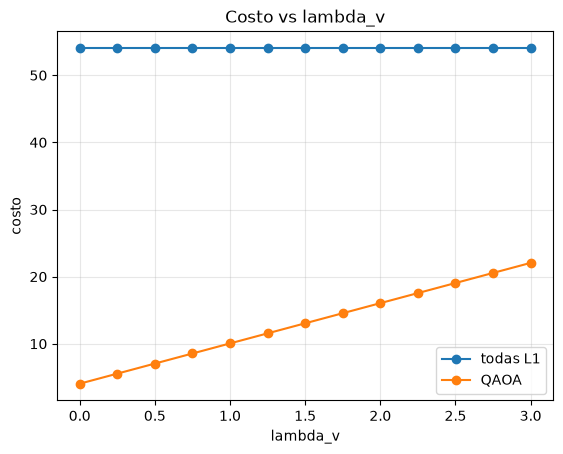

In [12]:
# lambda_v (costo por vía)
lams = np.linspace(0, 3, 13)
for name, bits in [("todas L1", [0]*n), ("QAOA", best["x"])]:
    vals = [M.full_cost(bits, prob["W"], prob["vias"], lv, prob["conflicts"], prob["M"]) for lv in lams]
    plt.plot(lams, vals, "o-", label=name)
plt.xlabel("lambda_v"); plt.ylabel("costo"); plt.title("Costo vs lambda_v")
plt.legend(); plt.grid(True, alpha=.3); plt.show()

## Notas

- La optimización QAOA vive en `quantum/fastqaoa.py` (mismo QAOA que `main.py`, en NumPy).
- El circuito que se envía a un backend usa **ángulos numéricos** (`qaoa.build_circuit`).
- Para IonQ **no transpilar** (su pipeline valida los ángulos).
- Cuando un experimento funcione aquí, se integra en `quantum/pipeline.py` y el visor.